# Lecture 17: Uncertainty Quantification

A surrogate prediction needs an error bar, and the error bar needs a check. In this notebook:

1. **Toy regression**: a network with a variance output, a deep ensemble and MC dropout. The aleatoric and epistemic parts of the variance.
2. **Burgers from 8 sensors**: a deep ensemble for the Lecture 16 task, its band and the two parts of its variance.
3. **Checking calibration**: coverage of intervals, error against predicted std, PIT and rank histograms, CRPS. We compare the ensemble with the Lecture 16 MSE and diffusion models.
4. **Split conformal prediction**: intervals with a coverage guarantee, and what happens to coverage when the sensors become noisy.

The models are trained checkpoints. No training in this notebook. The training code is at the end for offline runs (one HPC3 GPU).

In [1]:
import os, math, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import norm

torch.manual_seed(0)
torch.set_num_threads(4)

URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/"
FILES = {"lecture12": ["burgers_train_128.npz"],
         "lecture16": ["burgers_diff.pt", "burgers_mse.pt"],
         "lecture17": ["toy.pt"] + [f"ens_{s}.pt" for s in range(5)]}
for folder, files in FILES.items():
    os.makedirs(f"../data/{folder}", exist_ok=True)
    for f in files:
        path = f"../data/{folder}/{f}"
        if not os.path.exists(path):
            print("downloading", folder, f)
            urllib.request.urlretrieve(URL + f"{folder}/{f}", path)
D12, D16, D17 = "../data/lecture12/", "../data/lecture16/", "../data/lecture17/"
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})

### Networks

* `MLP`: the toy network, 3 hidden layers of 64 SiLU neurons, two outputs: the mean $\mu_\theta(x)$ and $\log\sigma^2_\theta(x)$. With `p > 0` it has dropout after each hidden layer.
* `UNet1d`: the Lecture 16 periodic U-Net. `UNetNLL` is the same network with two output channels, $\mu$ and $\log\sigma^2$.
* The Lecture 16 diffusion sampler `sample` is included to draw samples from the Lecture 16 diffusion model.

**Gaussian negative log-likelihood** (training loss of the variance networks):
$$\mathcal L(\theta) = \frac1N\sum_{i=1}^N\left[\frac{(y_i-\mu_\theta(x_i))^2}{2\sigma^2_\theta(x_i)} + \frac12\log\sigma^2_\theta(x_i)\right].$$

In [2]:
class MLP(nn.Module):
    def __init__(self, width=64, p=0.0):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(1, width), nn.SiLU(), nn.Dropout(p), nn.Linear(width, width), nn.SiLU(),
                                 nn.Dropout(p), nn.Linear(width, width), nn.SiLU(), nn.Dropout(p), nn.Linear(width, 2))
    def forward(self, x):
        h = self.net(x)
        return h[:, :1], h[:, 1:].clamp(-10, 3)          # mean, log-variance

def gaussian_nll(mu, logvar, y):
    return 0.5 * (logvar + (y - mu) ** 2 / logvar.exp()).mean()

# ---- Lecture 16 diffusion schedule and sampler ----
T_STEPS = 1000
def cosine_alpha_bar(T=T_STEPS, s=0.008):
    t = torch.arange(T + 1, dtype=torch.float64) / T
    f = torch.cos((t + s) / (1 + s) * math.pi / 2) ** 2
    ab = f / f[0]
    beta = (1 - ab[1:] / ab[:-1]).clamp(max=0.999)
    return torch.cumprod(1 - beta, 0).float()
ALPHA_BAR = cosine_alpha_bar()

@torch.no_grad()
def sample(model, shape, cond, steps=100, eta=1.0, gen=None, clip=6.0):
    x = torch.randn(shape, generator=gen)
    ts = torch.linspace(T_STEPS - 1, 0, steps).round().long()
    for i, t in enumerate(ts):
        ab = ALPHA_BAR[t]
        ab_prev = ALPHA_BAR[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        eps = model(x, torch.full((shape[0],), int(t), dtype=torch.long), cond)
        x0 = ((x - (1 - ab).sqrt() * eps) / ab.sqrt()).clamp(-clip, clip)
        eps = (x - ab.sqrt() * x0) / (1 - ab).sqrt()
        sigma = eta * ((1 - ab_prev) / (1 - ab) * (1 - ab / ab_prev)).clamp(min=0).sqrt()
        noise = torch.randn(shape, generator=gen) if i + 1 < len(ts) else torch.zeros(shape)
        x = ab_prev.sqrt() * x0 + (1 - ab_prev - sigma**2).clamp(min=0).sqrt() * eps + sigma * noise
    return x

def time_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half) / half)
    a = t.float()[:, None] * freqs[None]
    return torch.cat([a.sin(), a.cos()], 1)

# ---- Lecture 16 U-Net ----
class PConv(nn.Conv1d):
    def forward(self, x):
        p = self.kernel_size[0] // 2
        return super().forward(F.pad(x, (p, p), mode="circular"))

class ResBlock(nn.Module):
    def __init__(self, ci, co, temb):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, ci), PConv(ci, co, 3)
        self.t = nn.Linear(temb, co)
        self.n2, self.c2 = nn.GroupNorm(8, co), PConv(co, co, 3)
        self.skip = nn.Conv1d(ci, co, 1) if ci != co else nn.Identity()
    def forward(self, x, e):
        h = self.c1(F.silu(self.n1(x))) + self.t(e)[:, :, None]
        return self.c2(F.silu(self.n2(h))) + self.skip(x)

class UNet1d(nn.Module):
    def __init__(self, cin=2, ch=(32, 64, 96), temb=128):
        super().__init__()
        self.temb = temb
        self.emb = nn.Sequential(nn.Linear(temb, temb), nn.SiLU(), nn.Linear(temb, temb))
        self.inp = PConv(cin, ch[0], 3)
        self.down, c, skips = nn.ModuleList(), ch[0], [ch[0]]
        for co in ch:
            self.down.append(nn.ModuleList([ResBlock(c, co, temb), ResBlock(co, co, temb)])); c = co; skips.append(c)
        self.mid = nn.ModuleList([ResBlock(c, c, temb), ResBlock(c, c, temb)])
        self.up = nn.ModuleList()
        for co in reversed(ch):
            s = skips.pop()
            self.up.append(nn.ModuleList([ResBlock(c + s, co, temb), ResBlock(co, co, temb)])); c = co
        self.out = nn.Sequential(nn.GroupNorm(8, c), nn.SiLU(), PConv(c, 1, 3))
        self.nlev = len(ch)
    def forward(self, x, t, cond):
        e = self.emb(time_embedding(t, self.temb))
        h = self.inp(torch.cat([x, cond], 1)); hs = [h]
        for i, (b1, b2) in enumerate(self.down):
            h = b2(b1(h, e), e); hs.append(h)
            if i < self.nlev - 1: h = F.avg_pool1d(h, 2)
        for b in self.mid: h = b(h, e)
        for b1, b2 in self.up:
            s = hs.pop()
            if h.shape[-1] != s.shape[-1]: h = F.interpolate(h, size=s.shape[-1], mode="nearest")
            h = b2(b1(torch.cat([h, s], 1), e), e)
        return self.out(h)

class UNetNLL(UNet1d):
    # two output channels: mean and log-variance; input: the sensor field
    def __init__(self):
        super().__init__()
        self.out[-1] = PConv(self.out[-1].in_channels, 2, 3)
    def forward(self, cond):
        h = super().forward(torch.zeros_like(cond), torch.zeros(len(cond), dtype=torch.long), cond)
        return h[:, :1], h[:, 1:].clamp(-14, 4)

STRIDE = 16
def cond_of(y, stride=STRIDE):
    s = y[..., ::stride]; nxt = torch.roll(s, -1, -1)
    w = (torch.arange(y.shape[-1]) % stride).float() / stride
    return s.repeat_interleave(stride, -1) * (1 - w) + nxt.repeat_interleave(stride, -1) * w

---
## Part 1: Aleatoric and epistemic uncertainty on a toy problem

$y = \sin 3x + 0.3x + \sigma(x)\,\xi$ with $\xi \sim \mathcal N(0,1)$ and noise std $\sigma(x) = 0.04 + 0.25x^2$, growing with $|x|$. 256 training points on $[-1.2, -0.35] \cup [0.35, 1.2]$: a gap in the middle and no data beyond $|x| = 1.2$ (gray in the plots).

* **One network** with a variance output, trained with the Gaussian NLL (500 steps of MSE first, 3000 steps in total).
* **Deep ensemble**: 5 such networks with different seeds. Mixture mean $\mu_* = \frac1M\sum_m\mu_m$ and variance
$$\sigma_*^2 = \underbrace{\frac1M\sum_m\sigma_m^2}_{\text{aleatoric}} + \underbrace{\frac1M\sum_m(\mu_m-\mu_*)^2}_{\text{epistemic}}.$$
* **MC dropout**: one network with dropout $p = 0.1$, evaluated 100 times with dropout on.

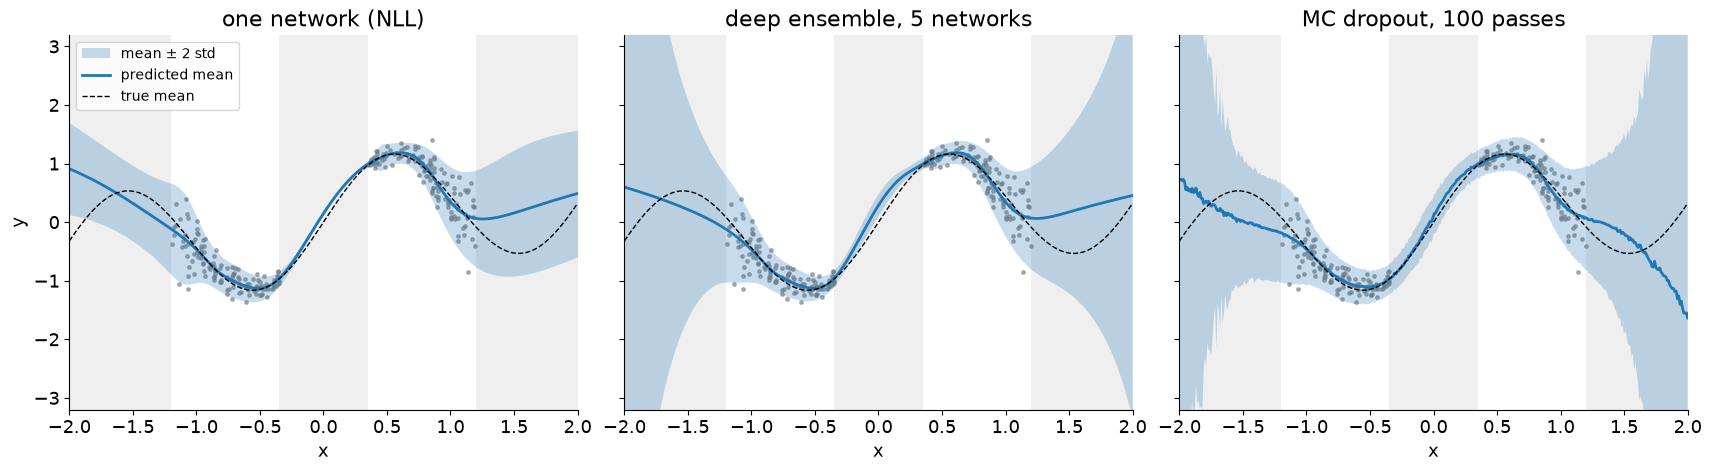

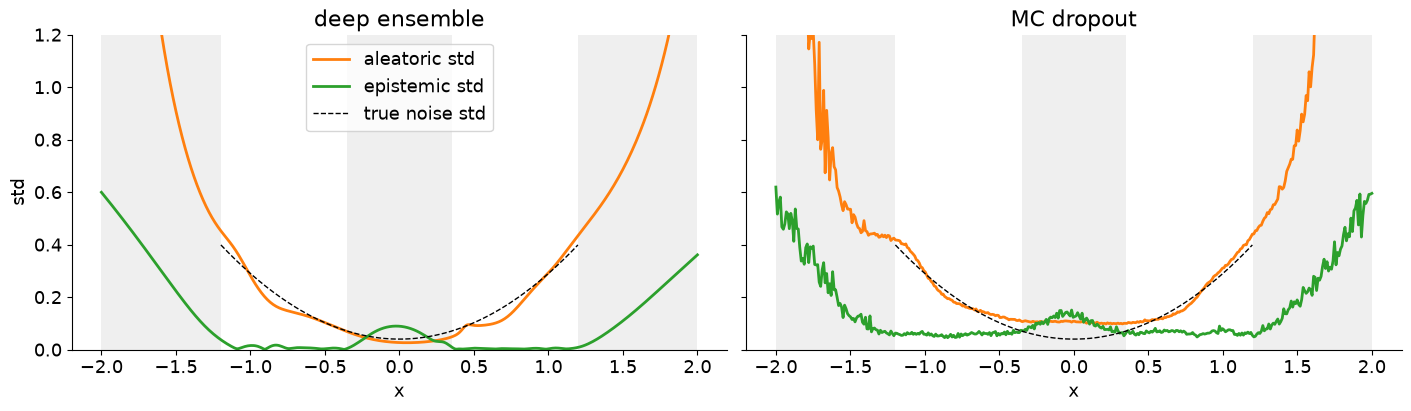

In [3]:
def f_true(x):   return np.sin(3 * x) + 0.3 * x
def sig_true(x): return 0.04 + 0.25 * np.abs(x) ** 2
def make_data(n, seed):
    r = np.random.default_rng(seed)
    x = np.concatenate([r.uniform(-1.2, -0.35, n // 2), r.uniform(0.35, 1.2, n - n // 2)])
    return x.astype(np.float32), (f_true(x) + sig_true(x) * r.standard_normal(n)).astype(np.float32)

xd, yd = make_data(256, seed=256)
ck = torch.load(D17 + "toy.pt")
members = []
for sd in ck["ens256"]:
    m = MLP(); m.load_state_dict(sd); members.append(m.eval())
drop = MLP(p=0.1); drop.load_state_dict(ck["dropout"])

xs = np.linspace(-2, 2, 400).astype(np.float32); X = torch.tensor(xs)[:, None]
with torch.no_grad():
    mus = np.stack([m(X)[0][:, 0].numpy() for m in members])
    vs = np.stack([m(X)[1][:, 0].exp().numpy() for m in members])
    drop.train()                                        # dropout on at test time
    dm = np.stack([drop(X)[0][:, 0].numpy() for _ in range(100)])
    dv = np.stack([drop(X)[1][:, 0].exp().numpy() for _ in range(100)])
mu_e, ale, epi = mus.mean(0), vs.mean(0), mus.var(0)
mu_d, ale_d, epi_d = dm.mean(0), dv.mean(0), dm.var(0)

def shade(a):
    for lo, hi in [(-2, -1.2), (-0.35, 0.35), (1.2, 2)]:
        a.axvspan(lo, hi, color="gray", alpha=0.12, lw=0)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained", sharey=True)
for a, (m, v, name) in zip(ax, [(mus[0], vs[0], "one network (NLL)"),
                                (mu_e, ale + epi, "deep ensemble, 5 networks"),
                                (mu_d, ale_d + epi_d, "MC dropout, 100 passes")]):
    shade(a)
    a.scatter(xd, yd, s=6, color="gray", alpha=0.6)
    a.fill_between(xs, m - 2 * np.sqrt(v), m + 2 * np.sqrt(v), alpha=0.25, color="C0", lw=0, label="mean ± 2 std")
    a.plot(xs, m, color="C0", lw=2, label="predicted mean")
    a.plot(xs, f_true(xs), "k--", lw=1, label="true mean")
    a.set(xlabel="x", title=name, ylim=(-3.2, 3.2), xlim=(-2, 2))
ax[0].set_ylabel("y"); ax[0].legend(loc="upper left", fontsize=10)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4), layout="constrained", sharey=True)
inside = np.abs(xs) <= 1.2
for a, (al, ep, name) in zip(ax, [(ale, epi, "deep ensemble"), (ale_d, epi_d, "MC dropout")]):
    shade(a)
    a.plot(xs, np.sqrt(al), color="C1", lw=2, label="aleatoric std")
    a.plot(xs, np.sqrt(ep), color="C2", lw=2, label="epistemic std")
    a.plot(xs[inside], sig_true(xs[inside]), "k--", lw=1, label="true noise std")
    a.set(xlabel="x", title=name, ylim=(0, 1.2))
ax[0].set_ylabel("std"); ax[0].legend(loc="upper center")
plt.show()

**What to observe**

* One network follows the noise inside the data. Outside the data its mean and its variance are extrapolations, and in places the band does not contain the true function.
* The ensemble members agree inside the data and disagree outside it. The ensemble band widens beyond $|x| = 1.2$. The epistemic std is close to zero inside the data and grows outside.
* Inside the data, the aleatoric std of the ensemble is close to the true noise std. Outside, the variance outputs are themselves extrapolations and grow quickly.
* MC dropout also widens outside the data. Its epistemic std does not go to zero inside the data and is noisy: its size depends on the dropout rate, a hyperparameter, more than on the data.
* In the small gap at $x = 0$, the epistemic std of both methods has only a small bump: the function is smooth there, and the networks interpolate it similarly.

---
## Part 2: A deep ensemble for the Burgers sensor task

Lecture 16 task: Lecture 12 Burgers data ($\nu = 0.01$, periodic $[0, 1)$, 128 points, times $t \ge 0.1$), scaled by $1/0.5$. The input is $u$ at 8 sensors (every 16th point), linearly interpolated to all 128 points.

Ensemble: 5 `UNetNLL` networks with seeds 0-4. Each: 800 steps of MSE on the mean, then **$\beta$-NLL** with $\beta = 1$ (Seitzer et al., ICLR 2022): the NLL of each point multiplied by its detached predicted variance, $\mathrm{sg}[\sigma^{2\beta}]\cdot\mathrm{NLL}$. With $\beta = 1$ the mean receives the MSE gradient, and the variance still converges to the expected squared error. The plain NLL gave a much worse mean on this task: its gradient for the mean is divided by $\sigma^2$, so the mean is neglected where the predicted variance is large. 4000 steps in total, Adam with a one-cycle schedule, batch 64, augmentation with periodic shifts and $u(x) \to -u(-x)$. Trajectories **0–799** for training, **800–899** held out for calibration (Part 4), **900–999** for testing.

In [4]:
u = np.load(D12 + "burgers_train_128.npz")["u"].astype(np.float32)
SC = 0.5
def fields(lo, hi, t0=5, t1=51):
    return torch.tensor(u[lo:hi, t0:t1]).reshape(-1, 128)[:, None] / SC

ens = []
for s in range(5):
    m = UNetNLL(); m.load_state_dict(torch.load(D17 + f"ens_{s}.pt")["state_dict"]); ens.append(m.eval())

@torch.no_grad()
def ens_pred(Y, models=ens, cond=None, bs=500):
    mus, vs = [], []
    for i in range(0, len(Y), bs):
        c = cond_of(Y[i:i + bs]) if cond is None else cond[i:i + bs]
        o = [m(c) for m in models]
        mus.append(torch.stack([a[0][:, 0] for a in o])); vs.append(torch.stack([a[1][:, 0].exp() for a in o]))
    return torch.cat(mus, 1).numpy(), torch.cat(vs, 1).numpy()   # (M, fields, 128)

def mixture(MU, V):
    return MU.mean(0), V.mean(0), MU.var(0)                     # mean, aleatoric var, epistemic var

Ytest, Ycal = fields(900, 1000), fields(800, 900)
yt, yc = Ytest[:, 0].numpy(), Ycal[:, 0].numpy()
MU, V = ens_pred(Ytest)
mu, ale, epi = mixture(MU, V); sd = np.sqrt(ale + epi)
print("test fields:", yt.shape, " fraction of the predictive variance that is aleatoric:", round(float(ale.mean() / (ale + epi).mean()), 3))

test fields: (4600, 128)  fraction of the predictive variance that is aleatoric: 0.905


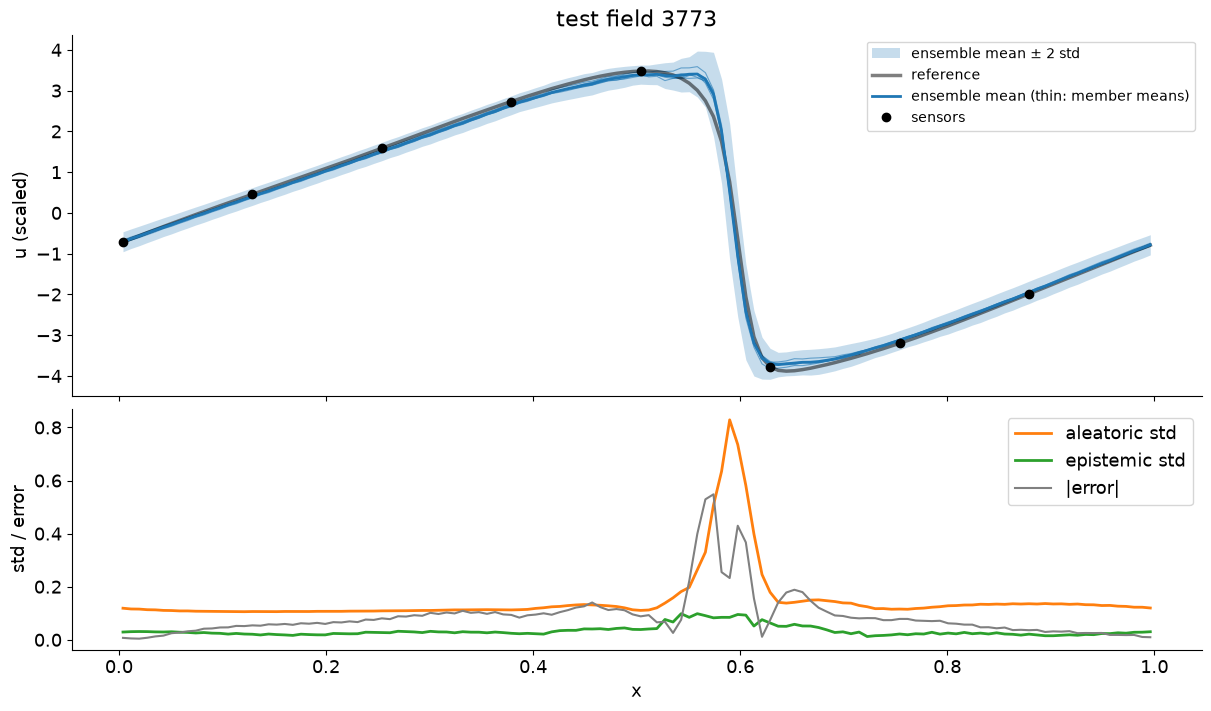

In [5]:
xg = (np.arange(128) + 0.5) / 128
i = int(np.argmax(sd.max(1)))                     # the test field with the largest predicted std
fig, ax = plt.subplots(2, 1, figsize=(12, 7), layout="constrained", sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
ax[0].fill_between(xg, mu[i] - 2 * sd[i], mu[i] + 2 * sd[i], alpha=0.25, color="C0", lw=0, label="ensemble mean ± 2 std")
for m in MU[:, i]:
    ax[0].plot(xg, m, color="C0", lw=0.8, alpha=0.6)
ax[0].plot(xg, yt[i], "k", lw=2.5, alpha=0.5, label="reference")
ax[0].plot(xg, mu[i], "C0", lw=2, label="ensemble mean (thin: member means)")
ax[0].plot(xg[::STRIDE], yt[i, ::STRIDE], "ko", ms=6, label="sensors")
ax[0].set(ylabel="u (scaled)", title=f"test field {i}"); ax[0].legend(fontsize=10)
ax[1].plot(xg, np.sqrt(ale[i]), "C1", lw=2, label="aleatoric std")
ax[1].plot(xg, np.sqrt(epi[i]), "C2", lw=2, label="epistemic std")
ax[1].plot(xg, np.abs(mu[i] - yt[i]), "gray", lw=1.5, label="|error|")
ax[1].set(xlabel="x", ylabel="std / error"); ax[1].legend()
plt.show()

**What to observe**

* On the ramps the band is thin and the reference lies inside it: the sensors determine the field.
* Around the front between two sensors the band is wide, and the error of the mean is large there too.
* The member means (thin lines) nearly coincide: the epistemic std is much smaller than the aleatoric std. Each member predicts a large variance at the front. The uncertainty comes from the missing information between sensors, not from a lack of training data.

---
## Part 3: Checking calibration

We compare on 300 test fields:

* **single network**: ensemble member 0, Gaussian with its own $\mu$ and $\sigma$
* **ensemble**: the 5-member mixture
* **ensemble means only**: the spread of the 5 means without the variance outputs (what an ensemble of MSE models produces)
* **diffusion**: the Lecture 16 diffusion model, 8 samples per field
* **MSE model**: the Lecture 16 point prediction 

Checks:

* **Coverage**: the fraction of targets inside the central interval with probability $p$, for several $p$. Calibrated: coverage $= p$.
* **Error against predicted std**: group points into bins by predicted std; compare the RMSE in each bin with the mean predicted std.
* **PIT histogram** $F_i(y_i)$ for the ensemble and **rank histogram** for the diffusion samples: flat if calibrated.
* **Spread-skill ratio** $\sqrt{(M+1)/M}\;\text{spread}/\text{RMSE}$ for the sample-based models; $\sqrt{\overline{\sigma_*^2}}/\text{RMSE}$ for the Gaussian ones.
* **CRPS** $= \mathbb E|Y - y| - \tfrac12\mathbb E|Y - Y'|$, computed from samples (for the mixture, 64 samples per point). For the MSE model it is the absolute error.

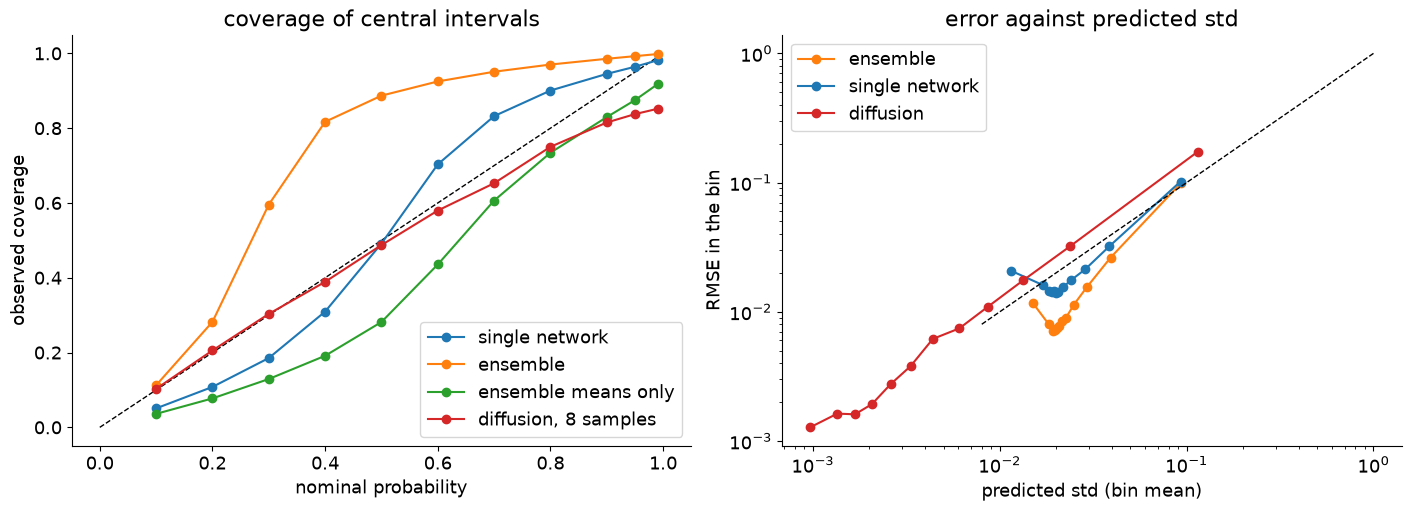

single network         coverage of the 50% interval: 0.49   of the 90% interval: 0.95
ensemble               coverage of the 50% interval: 0.89   of the 90% interval: 0.99
ensemble means only    coverage of the 50% interval: 0.28   of the 90% interval: 0.83
diffusion, 8 samples   coverage of the 50% interval: 0.49   of the 90% interval: 0.82


In [6]:
torch.manual_seed(0)
sel = torch.randperm(len(Ytest))[:300].numpy()
Y, ys = Ytest[sel], yt[sel]

def load_unet(name):
    m = UNet1d(); m.load_state_dict(torch.load(D16 + name + ".pt")["state_dict"]); return m.eval()
diff, msem = load_unet("burgers_diff"), load_unet("burgers_mse")
with torch.no_grad():
    mse = msem(torch.zeros_like(Y), torch.zeros(len(Y), dtype=torch.long), cond_of(Y))[:, 0].numpy()
    c = cond_of(Y).repeat(8, 1, 1)
    S = sample(diff, c.shape, cond=c, steps=100, gen=torch.Generator().manual_seed(5))[:, 0].numpy().reshape(8, 300, 128)

MUs, Vs = MU[:, sel], V[:, sel]
mus_, ales_, epis_ = mixture(MUs, Vs); sds_ = np.sqrt(ales_ + epis_)
levels = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99])

def coverage_gauss(m, s, y):
    z = np.abs(y - m) / s
    return np.array([(z <= norm.ppf(0.5 + p / 2)).mean() for p in levels])
def coverage_samples(S, y):
    return np.array([((y >= np.quantile(S, 0.5 - p / 2, axis=0)) & (y <= np.quantile(S, 0.5 + p / 2, axis=0))).mean() for p in levels])

cov = {"single network": coverage_gauss(MUs[0], np.sqrt(Vs[0]), ys),
       "ensemble": coverage_gauss(mus_, sds_, ys),
       "ensemble means only": coverage_gauss(mus_, np.sqrt(epis_), ys),
       "diffusion, 8 samples": coverage_samples(S, ys)}

def binned(sd_pred, err, nb=12):
    q = np.quantile(sd_pred, np.linspace(0, 1, nb + 1)); idx = np.clip(np.digitize(sd_pred, q[1:-1]), 0, nb - 1)
    return np.array([sd_pred[idx == b].mean() for b in range(nb)]), np.array([np.sqrt((err[idx == b] ** 2).mean()) for b in range(nb)])

fig, ax = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
COL = {"single network": "C0", "ensemble": "C1", "ensemble means only": "C2", "diffusion, 8 samples": "C3", "diffusion": "C3"}
for name, cv in cov.items():
    ax[0].plot(levels, cv, "o-", color=COL[name], label=name)
ax[0].set(xlabel="nominal probability", ylabel="observed coverage", title="coverage of central intervals"); ax[0].legend()
for name, (sp, er) in {"ensemble": (sds_, mus_ - ys), "single network": (np.sqrt(Vs[0]), MUs[0] - ys),
                       "diffusion": (S.std(0, ddof=1) * np.sqrt(9 / 8), S.mean(0) - ys)}.items():
    b = binned(sp.ravel(), er.ravel()); ax[1].loglog(*b, "o-", color=COL[name], label=name)
lim = [sds_.min() + 1e-4, 1]
ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set(xlabel="predicted std (bin mean)", ylabel="RMSE in the bin", title="error against predicted std"); ax[1].legend()
plt.show()
for name, cv in cov.items():
    print(f"{name:22s} coverage of the 50% interval: {cv[4]:.2f}   of the 90% interval: {cv[8]:.2f}")

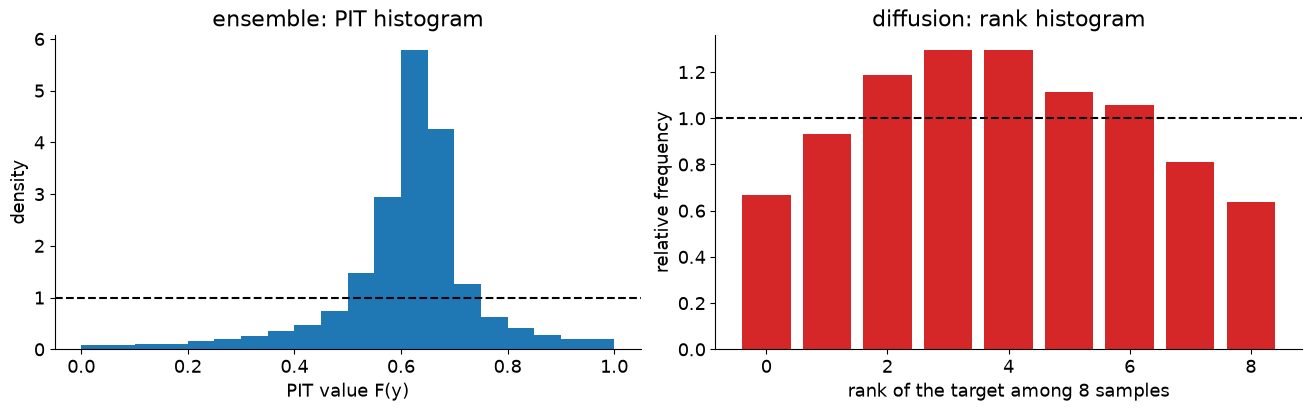

model                   RMSE of mean     CRPS  spread-skill
MSE model                     0.0295   0.0101             -
single network                0.0343   0.0136          1.11
ensemble                      0.0308   0.0106          1.25
ensemble means only           0.0308   0.0097          0.48
diffusion (8 samples)         0.0514   0.0088          0.98


ensemble                      0.0308   0.0106          1.25
ensemble means only           0.0308   0.0097          0.48
diffusion (8 samples)         0.0514   0.0088          0.98


In [7]:
pit = norm.cdf((ys[None] - MUs) / np.sqrt(Vs)).mean(0).ravel()     # mixture CDF at the target
rank = (S < ys[None]).sum(0).ravel()                                # rank of the target among 8 samples
fig, ax = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
ax[0].hist(pit, bins=20, density=True, color="C0"); ax[0].axhline(1, color="k", ls="--")
ax[0].set(xlabel="PIT value F(y)", ylabel="density", title="ensemble: PIT histogram")
ax[1].bar(np.arange(9), np.bincount(rank, minlength=9) / len(rank) * 9, color="C3"); ax[1].axhline(1, color="k", ls="--")
ax[1].set(xlabel="rank of the target among 8 samples", ylabel="relative frequency", title="diffusion: rank histogram")
plt.show()

def crps_samples(S, y):                    # fair (unbiased) CRPS from M samples
    M = len(S)
    return (np.abs(S - y[None]).mean(0) - 0.5 * np.abs(S[:, None] - S[None]).sum((0, 1)) / (M * (M - 1))).mean()
def mixture_samples(MU, V, n=64, seed=0):
    r = np.random.default_rng(seed); k = r.integers(0, len(MU), (n,) + MU.shape[1:])
    return np.take_along_axis(MU, k, 0) + np.sqrt(np.take_along_axis(V, k, 0)) * r.standard_normal(k.shape)
def ss_ratio(Sm, y):
    M = len(Sm); return np.sqrt((M + 1) / M) * np.sqrt(Sm.var(0, ddof=1).mean()) / np.sqrt(((Sm.mean(0) - y) ** 2).mean())
rmse = lambda a: np.sqrt(((a - ys) ** 2).mean())

single = mixture_samples(MUs[:1], Vs[:1])
print(f"{'model':22s} {'RMSE of mean':>13s} {'CRPS':>8s} {'spread-skill':>13s}")
print(f"{'MSE model':22s} {rmse(mse):13.4f} {np.abs(mse - ys).mean():8.4f} {'-':>13s}")
print(f"{'single network':22s} {rmse(MUs[0]):13.4f} {crps_samples(single, ys):8.4f} {np.sqrt(Vs[0].mean()) / rmse(MUs[0]):13.2f}")
print(f"{'ensemble':22s} {rmse(mus_):13.4f} {crps_samples(mixture_samples(MUs, Vs), ys):8.4f} {np.sqrt((sds_**2).mean()) / rmse(mus_):13.2f}")
print(f"{'ensemble means only':22s} {rmse(mus_):13.4f} {crps_samples(MUs, ys):8.4f} {ss_ratio(MUs, ys):13.2f}")
print(f"{'diffusion (8 samples)':22s} {rmse(S.mean(0)):13.4f} {crps_samples(S, ys):8.4f} {ss_ratio(S, ys):13.2f}")

**What to observe**

* One network is close to calibrated at the 50% and 90% levels.
* The ensemble is **over-dispersed**: its intervals contain more targets than their nominal probability. Each member's variance matches the error of that member, and the ensemble mean is more accurate than a member, so the mixture variance is too large for the ensemble mean.
* The ensemble means alone are under-dispersed: on this task most of the uncertainty is aleatoric, and an ensemble without variance outputs misses it.
* The diffusion intervals from 8 samples undercover at high probabilities: the range of 8 samples is a coarse estimate of a 90% interval. The rank histogram is the better check for few samples. It is close to flat with a mild dome.
* In the binned plot, the RMSE grows with the predicted std: the uncertainty ranks the points correctly. The ensemble bins lie below the diagonal: more predicted spread than error.
* The ensemble's PIT histogram has a peak: too much spread. The peak is off-center: the targets lie slightly above the ensemble mean more often than below, a small bias of the mean that the coverage plot does not show.
* The diffusion samples have the lowest CRPS. The ensemble's excess spread makes its CRPS slightly worse than the MSE model's absolute error. Scaling $\sigma_*$ down (Exercise 1) corrects this. The exact numbers depend on seeds and training so the ordering is what to compare.

---
## Part 4: Split conformal prediction

Score on the calibration set (trajectories 800–899, all times and points): $s_i = |y_i - \mu_*(x_i)| / \sigma_*(x_i)$. With $n$ scores and $\alpha = 0.1$,
$$\hat q = \text{quantile of } s_1, \dots, s_n \text{ at level } \lceil (n+1)(1-\alpha)\rceil / n, \qquad C(x) = [\mu_* - \hat q\,\sigma_*,\ \mu_* + \hat q\,\sigma_*].$$
If the test pairs are exchangeable with the calibration pairs, $P(y \in C(x)) \ge 1 - \alpha$, on average over test points.

We compare with the Gaussian 90% interval ($\hat q = 1.645$) and with a constant width ($\sigma = 1$: the score is the absolute residual).

q-hat = 0.703  (Gaussian: 1.645)
Gaussian 90% interval:        coverage 0.985, mean width 0.093
conformal, scaled by std:     coverage 0.898, mean width 0.040
conformal, constant width:    coverage 0.899, width 0.043


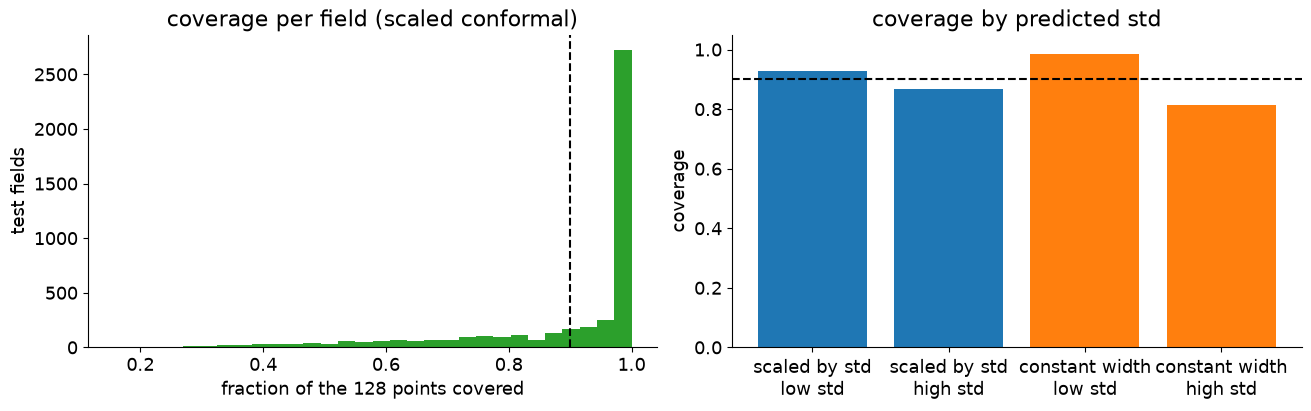

In [8]:
alpha = 0.1
MUc, Vc = ens_pred(Ycal)
muc, alec, epic = mixture(MUc, Vc); sdc = np.sqrt(alec + epic)

def conformal_q(scores, alpha):
    n = scores.size
    return np.quantile(scores, np.ceil((n + 1) * (1 - alpha)) / n, method="higher")

qhat = conformal_q((np.abs(yc - muc) / sdc).ravel(), alpha)
qabs = conformal_q(np.abs(yc - muc).ravel(), alpha)
z = norm.ppf(1 - alpha / 2)
inside = lambda half: np.abs(yt - mu) <= half
print(f"q-hat = {qhat:.3f}  (Gaussian: {z:.3f})")
print(f"Gaussian 90% interval:        coverage {inside(z * sd).mean():.3f}, mean width {2 * z * sd.mean():.3f}")
print(f"conformal, scaled by std:     coverage {inside(qhat * sd).mean():.3f}, mean width {2 * qhat * sd.mean():.3f}")
print(f"conformal, constant width:    coverage {inside(qabs).mean():.3f}, width {2 * qabs:.3f}")

per_field = inside(qhat * sd).mean(1)
ramp = sd < np.quantile(sd, 0.5)                     # points with predicted std below the median
fig, ax = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
ax[0].hist(per_field, bins=30, color="C2"); ax[0].axvline(0.9, color="k", ls="--")
ax[0].set(xlabel="fraction of the 128 points covered", ylabel="test fields", title="coverage per field (scaled conformal)")
for name, half in [("scaled by std", qhat * sd), ("constant width", np.full_like(sd, qabs))]:
    ins = np.abs(yt - mu) <= half
    ax[1].bar([f"{name}\nlow std", f"{name}\nhigh std"], [ins[ramp].mean(), ins[~ramp].mean()])
ax[1].axhline(0.9, color="k", ls="--"); ax[1].set(ylim=(0, 1.05), ylabel="coverage", title="coverage by predicted std")
plt.show()

**What to observe**

* Both conformal intervals cover close to 90% of the test points: the guarantee holds because the test trajectories come from the same distribution as the calibration trajectories.
* The ensemble is over-dispersed, so its Gaussian 90% interval covers nearly all test points. The conformal $\hat q$ is well below 1.645, and the interval is less than half as wide.
* The guarantee is marginal. Coverage per field varies widely: some fields are covered at all 128 points, others at far fewer.
* With a constant width, coverage is too high where the predicted std is low (ramps) and too low where it is high (fronts). Scaling by the ensemble std distributes the coverage more evenly and the intervals are narrow where the model is confident.

### Coverage under a distribution shift: noisy sensors

The models never saw noisy sensor values. We add Gaussian noise to the 8 sensor values of the test fields (scaled units, the scaled fields are of order 1) and use $\hat q$ from the clean calibration set.

In [9]:
def noisy_cond(Y, amp, seed=1):
    g = torch.Generator().manual_seed(seed)
    s = Y[..., ::STRIDE] + amp * torch.randn(Y[..., ::STRIDE].shape, generator=g)
    nxt = torch.roll(s, -1, -1); w = (torch.arange(128) % STRIDE).float() / STRIDE
    return s.repeat_interleave(STRIDE, -1) * (1 - w) + nxt.repeat_interleave(STRIDE, -1) * w

print(f"{'sensor noise std':>17s} {'coverage':>9s} {'RMSE':>8s} {'mean predicted std':>19s}")
for amp in [0.0, 0.05, 0.1, 0.2]:
    Mn, Vn = ens_pred(Y, cond=noisy_cond(Y, amp))
    mn, an, en = mixture(Mn, Vn); sn = np.sqrt(an + en)
    print(f"{amp:17.2f} {(np.abs(ys - mn) <= qhat * sn).mean():9.3f} {np.sqrt(((mn - ys) ** 2).mean()):8.4f} {sn.mean():19.4f}")

 sensor noise std  coverage     RMSE  mean predicted std
             0.00     0.896   0.0308              0.0286
             0.05     0.249   0.0821              0.0301
             0.10     0.149   0.1470              0.0330
             0.20     0.097   0.2592              0.0411


             0.05     0.249   0.0821              0.0301


             0.10     0.149   0.1470              0.0330


             0.20     0.097   0.2592              0.0411


**What to observe**

* As the sensor noise grows, the error grows faster than the predicted std, and coverage falls below 90%.
* Test and calibration data are no longer exchangeable, so the conformal guarantee does not apply. Recalibrating with a few noisy-sensor fields would restore coverage, at the price of wider intervals.

---
## Exercises

1. **Recalibrate by scaling.** Find one factor $c$ such that $\mu_* \pm 1.645\,c\,\sigma_*$ covers 90% of the calibration set. Compare $c$ with $\hat q / 1.645$, and check the coverage of the 50% interval after scaling.
2. **Ensemble size.** Compute coverage, CRPS and the epistemic fraction with $M = 1, 2, 3, 5$ members. Which quantities change most?
3. **Calibrate on the shifted data.** Compute $\hat q$ on calibration fields with sensor noise 0.1, and test on noisy test fields. What happens to coverage and width?
4. **MC dropout for Burgers (offline).** Add dropout to the U-Net, train with the NLL, and compare its coverage and CRPS with the ensemble.

In [10]:
# Training code (used for the checkpoints; run offline, e.g. on one HPC3 GPU)
import copy

def train_toy_member(x, y, seed, steps=3000, warm=500, p=0.0):
    torch.manual_seed(seed)
    m = MLP(p=p); X, Yt = torch.tensor(x)[:, None], torch.tensor(y)[:, None]
    opt = torch.optim.Adam(m.parameters(), lr=3e-3); sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for it in range(steps):
        mu, lv = m(X)
        loss = F.mse_loss(mu, Yt) if it < warm else gaussian_nll(mu, lv, Yt)
        opt.zero_grad(); loss.backward(); opt.step(); sch.step()
    return m
# toy.pt: {"ens256": [train_toy_member(xd, yd, s).state_dict() for s in range(5)],
#          "dropout": train_toy_member(xd, yd, 0, p=0.1).state_dict()}

def beta_nll(mu, logvar, y, beta=1.0):
    nll = 0.5 * (logvar + (y - mu) ** 2 / logvar.exp())
    return (nll * logvar.detach().exp() ** beta).mean()

def train_burgers_member(seed, steps=4000, warm=800, B=64, ntraj=800, device="cpu"):
    torch.manual_seed(seed)
    utr = (torch.tensor(u[:ntraj, 5:]).reshape(-1, 128) / SC).to(device)
    model = UNetNLL().to(device); ema = copy.deepcopy(model)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=steps, pct_start=0.03)
    for it in range(steps):
        y = utr[torch.randint(0, len(utr), (B,), device=device)][:, None]
        y = torch.roll(y, int(torch.randint(0, 128, ())), -1)
        if torch.rand(()) < 0.5:
            y = -torch.flip(y, [-1])
        mu, lv = model(cond_of(y))
        loss = F.mse_loss(mu, y) + 0.0 * lv.mean() if it < warm else beta_nll(mu, lv, y)
        opt.zero_grad(); loss.backward(); opt.step(); sch.step()
        with torch.no_grad():
            for pe, pm in zip(ema.parameters(), model.parameters()):
                pe.mul_(0.999).add_(pm, alpha=0.001)
    torch.save({"state_dict": ema.cpu().state_dict(), "seed": seed, "ntraj": ntraj}, f"ens_{seed}.pt")
    return ema
# for s in range(5): train_burgers_member(s, device="cuda")